Дані

In [2]:
import os, re, gc, glob, time
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
import xgboost as xgb
from xgboost import XGBClassifier
from scipy import stats
from sklearn.metrics import average_precision_score
from sklearn.preprocessing import QuantileTransformer
import matplotlib.pyplot as plt

os.makedirs("results/figures", exist_ok=True)
dev = torch.device("cuda")

def find(name):
    hits = glob.glob(f"/kaggle/input/**/{name}", recursive=True)
    assert hits, f"не знайшов {name}: перевір Add Input"
    return hits[0]

tr = pd.read_csv(find("train_transaction.csv"))
idn = pd.read_csv(find("train_identity.csv"))
for c in tr.select_dtypes("float64").columns:
    tr[c] = tr[c].astype("float32")
df = tr.merge(idn, on="TransactionID", how="left")
df["has_identity"] = df["TransactionID"].isin(idn["TransactionID"])
del tr

N = len(df)
ts, tid = df.TransactionDT.values, df.TransactionID.values
y = df.isFraud.values
w = (ts // 86400) // 7
m_tr, m_va, m_te = (w <= 17), (w >= 18) & (w <= 21), (w >= 22)
assert (m_tr.sum(), m_va.sum(), m_te.sum()) == (431125, 77090, 82325)
assert y.sum() == 20663
split_of = np.where(m_tr, 0, np.where(m_va, 1, 2))
order = np.lexsort((tid, ts)); rank = np.empty(N, np.int64); rank[order] = np.arange(N)

X = df.drop(columns=["TransactionID", "isFraud", "TransactionDT"]).copy()
X["hour"] = (df.TransactionDT // 3600) % 24
X["weekday"] = (df.TransactionDT // 86400) % 7
X["has_identity"] = X["has_identity"].astype("int8")
for c in X.select_dtypes(include=["object", "category"]).columns:
    codes, _ = pd.factorize(X[c])
    X[c] = np.where(codes == -1, np.nan, codes).astype("float32")
df["D1n"] = (df["D1"] - df["TransactionDT"] / 86400).round()      # після X: у таблицю не потрапляє

FP = ["DeviceInfo", "id_30", "id_31", "id_33"]                    # конфігурація пристрою
fp_has = df[FP].notna().all(axis=1).values
fp_str = df[FP[0]].astype(str).str.cat([df[c].astype(str) for c in FP[1:]], sep="|").values
real_dev = np.where(fp_has, fp_str, None).astype(object)

major = int(xgb.__version__.split(".")[0])
DEV = dict(tree_method="hist", device="cuda") if major >= 2 else dict(tree_method="gpu_hist")
print("готово:", X.shape, "| рядків з відбитком:", int(fp_has.sum()))

готово: (590540, 434) | рядків з відбитком: 71120


Cвіт з кільцями, граф, ознаки, перевірки

In [3]:
# ---- ознаки таблиці для нейромереж: рахуємо ОДИН раз (таблиця в усіх світах однакова) ----
Xn = X.values.astype("float32")
grp = lambda p: [i for i, c in enumerate(X.columns) if re.fullmatch(p, c)]
nanf = np.stack([np.isnan(Xn[:, g]).mean(1) for g in
                 (grp(r"V\d+"), grp(r"D\d+"), grp(r"id_\d+"), grp(r"M\d+"))], 1).astype("float32")
qt = QuantileTransformer(n_quantiles=200, output_distribution="normal",
                         subsample=200_000, random_state=0).fit(Xn[m_tr])
XT = np.hstack([np.nan_to_num(qt.transform(Xn), nan=0.0).clip(-5, 5).astype("float32"), nanf])
del Xn; gc.collect()

# ---- кільця: перепризначення справжніх чесних рядків ----
P_WEEKS = {"train": (0, 17), "val": (18, 21), "test": (22, 26)}
SPLIT_ID = {"train": 0, "val": 1, "test": 2}

def build_ring_rows(span_days, per_week, ring_seed):
    rng = np.random.default_rng(ring_seed)
    used = np.zeros(N, bool); span = int(span_days * 86400)
    rows_l, rid_l, per_l = [], [], []; rid = 0
    for name, (w0, w1) in P_WEEKS.items():
        sel = (w >= w0) & (w <= w1)
        p0, p1 = int(ts[sel].min()), int(ts[sel].max())
        pool = np.flatnonzero((y == 0) & fp_has & sel)
        pool = pool[np.argsort(ts[pool], kind="stable")]; tpool = ts[pool]
        for _ in range(per_week * (w1 - w0 + 1)):
            m = int(rng.integers(4, 9)); chosen = None
            for _try in range(500):
                t0 = rng.uniform(p0, p1 - span)
                lo = np.searchsorted(tpool, t0, side="left")
                hi = np.searchsorted(tpool, t0 + span, side="right")
                cand = pool[lo:hi]; cand = cand[~used[cand]]
                if len(cand) < m: continue
                vc = pd.Series(fp_str[cand]).value_counts(); vc = vc[vc >= m]
                if len(vc) == 0: continue
                g = vc.index[rng.choice(len(vc), p=vc.values / vc.values.sum())]
                chosen = rng.choice(cand[fp_str[cand] == g], m, replace=False); break
            assert chosen is not None, "не знайшов групу для кільця: зменш per_week"
            used[chosen] = True
            rows_l += list(chosen); rid_l += [rid] * m; per_l += [name] * m; rid += 1
    return np.array(rows_l), np.array(rid_l), np.array(per_l)

# ---- мітки сусідів і ребра за ключами світу ----
def label_feats2(cols, W_days, DLd):
    valid = KEYDF[cols].notna().all(axis=1).values; idx = np.flatnonzero(valid)
    nk = np.full(N, np.nan, "float32"); fk = np.full(N, np.nan, "float32")
    for pos in KEYDF.loc[valid, cols].groupby(cols, sort=False).indices.values():
        rows = idx[pos]; rows = rows[np.argsort(rank[rows], kind="stable")]
        tt, ff = ts[rows], y2[rows]; cs = np.concatenate([[0], np.cumsum(ff)])
        a = np.searchsorted(tt, tt, side="left")
        hi = np.minimum(np.searchsorted(tt, tt - DLd * 86400, side="right"), a)
        lo = np.minimum(np.searchsorted(tt, tt - W_days * 86400, side="left"), hi)
        nk[rows] = hi - lo; fk[rows] = cs[hi] - cs[lo]
    return nk, fk

def build_edges2(cols, K, W_days):
    valid = KEYDF[cols].notna().all(axis=1).values; idx = np.flatnonzero(valid)
    S, D = [], []
    for pos in KEYDF.loc[valid, cols].groupby(cols, sort=False).indices.values():
        if len(pos) < 2: continue
        rows = idx[pos]; rows = rows[np.argsort(rank[rows], kind="stable")]
        tt = ts[rows]; n = len(rows)
        lo = np.maximum(np.arange(n) - K, np.searchsorted(tt, tt - W_days * 86400, side="left"))
        cnt = np.arange(n) - lo; tot = int(cnt.sum())
        if tot == 0: continue
        dst_l = np.repeat(np.arange(n), cnt)
        start = np.repeat(np.cumsum(cnt) - cnt, cnt)
        src_l = np.arange(tot) - start + np.repeat(lo, cnt)
        S.append(rows[src_l].astype(np.int32)); D.append(rows[dst_l].astype(np.int32))
    return np.concatenate(S), np.concatenate(D)

REL2 = {"u2": (["gcard", "addr1"], 50, 30),
        "u3": (["gcard", "addr1", "P_emaildomain"], 50, 30),
        "u5": (["gcard", "addr1", "P_emaildomain", "D1n"], 50, 30),
        "dk": (["dev"], 50, 30)}
R_NAMES = list(REL2); KMAX = {k: v[1] for k, v in REL2.items()}

def hand_feats():
    Fd = {}
    for rel in ("u2", "u3", "u5"):
        nk, fk = label_feats2(REL2[rel][0], 30, 7)
        Fd[f"{rel}_nk"], Fd[f"{rel}_fk"] = nk, fk
        Fd[f"{rel}_rate"] = (fk / np.where(nk > 0, nk, np.nan)).astype("float32")
    D, DC = ["dev"], ["dev", "gcard"]
    n30, _ = label_feats2(D, 30, 0); n30s, _ = label_feats2(DC, 30, 0)   # лічильники без міток
    n7, _ = label_feats2(D, 7, 0);   n7s, _ = label_feats2(DC, 7, 0)
    Fd["dk_other30"], Fd["dk_other7"] = n30 - n30s, n7 - n7s            # ІНШІ картки на пристрої раніше
    nk, fk = label_feats2(D, 30, 7); nks, fks = label_feats2(DC, 30, 7)
    Fd["dk_nk"], Fd["dk_fk"] = nk - nks, fk - fks                       # відомі (затримка 7 днів) мітки, інші картки
    Fd["dk_rate"] = (Fd["dk_fk"] / np.where(Fd["dk_nk"] > 0, Fd["dk_nk"], np.nan)).astype("float32")
    return pd.DataFrame(Fd)

def check_hand(HF, n=50, seed=0):
    rng = np.random.default_rng(seed); bad = 0
    dv, gc_ = KEYDF["dev"].values, KEYDF["gcard"].values
    for i in rng.choice(np.flatnonzero(~np.isnan(dv)), n, replace=False):
        oth = (dv == dv[i]) & (gc_ != gc_[i])
        e30 = oth & (ts < ts[i]) & (ts >= ts[i] - 30 * 86400)
        e7 = oth & (ts < ts[i]) & (ts >= ts[i] - 7 * 86400)
        kn = oth & (ts <= ts[i] - 7 * 86400) & (ts >= ts[i] - 30 * 86400)
        g = HF.iloc[i]
        if (int(e30.sum()) != int(g["dk_other30"]) or int(e7.sum()) != int(g["dk_other7"]) or
                int(kn.sum()) != int(g["dk_nk"]) or int(y2[kn].sum()) != int(g["dk_fk"])): bad += 1
    k5 = KEYDF[["gcard", "addr1", "P_emaildomain", "D1n"]].values
    for i in rng.choice(np.flatnonzero(~np.isnan(k5).any(axis=1)), n, replace=False):
        same = (k5 == k5[i]).all(axis=1)
        kn = same & (ts <= ts[i] - 7 * 86400) & (ts >= ts[i] - 30 * 86400)
        if int(kn.sum()) != int(HF["u5_nk"].values[i]) or int(y2[kn].sum()) != int(HF["u5_fk"].values[i]): bad += 1
    return bad

def make_inputs(HF):
    cols_ = []
    for r in ("u2", "u3", "u5"):
        g = lambda k, r=r: np.nan_to_num(HF[f"{r}_{k}"].values)
        cols_ += [np.log1p(g("nk")), np.log1p(g("fk")), g("rate"), (g("nk") > 0).astype("float32")]
    g = lambda k: np.nan_to_num(HF[k].values)
    cols_ += [np.log1p(g("dk_other30")), np.log1p(g("dk_other7")), np.log1p(g("dk_nk")),
              np.log1p(g("dk_fk")), g("dk_rate"), HF["dk_other30"].notna().values.astype("float32")]
    M = np.stack(cols_, 1).astype("float32")
    M = (M - M[m_tr].mean(0)) / (M[m_tr].std(0) + 1e-6)
    return torch.from_numpy(np.hstack([XT, M])).half().to(dev)

def leak_test():
    sp_t = torch.as_tensor(split_of, device=dev); t_t = torch.as_tensor(ts, device=dev)
    rg_ = np.random.default_rng(0)
    for sp, cap in [(0, 0), (1, 1)]:
        ids = torch.as_tensor(rg_.choice(np.flatnonzero(split_of == sp), 4000, replace=False), device=dev)
        N1, M1, N2_, M2 = hops(ids, 10, 5)
        assert (sp_t[N1[M1]] <= cap).all() and (sp_t[N2_[M2]] <= cap).all(), "сусіди з майбутньої частини"
        assert (t_t[N1] <= t_t[ids][:, None, None])[M1].all(), "сусід пізніший за вузол (крок 1)"
        assert (t_t[N2_] <= t_t[N1][:, :, :, None, None])[M2].all(), "сусід пізніший за вузол (крок 2)"

def setup_world(span_days, ring_seed, per_week=10):
    global y2, is_ring, KEYDF, NBR, DEG, XG2, HF, XA, XB
    NBR = DEG = XG2 = HF = XA = XB = None
    gc.collect(); torch.cuda.empty_cache()
    rows, rid_a, per_a = build_ring_rows(span_days, per_week, ring_seed)
    R = len(rows)
    # --- перевірки конструкції кілець ---
    assert len(np.unique(rows)) == R and (y[rows] == 0).all() and fp_has[rows].all()
    assert pd.Series(fp_str[rows]).groupby(rid_a).nunique().max() == 1, "у кільці різні конфігурації пристрою"
    spread = pd.Series(ts[rows]).groupby(rid_a).agg(lambda s: s.max() - s.min())
    assert spread.max() <= span_days * 86400, "кільце розтягнуте довше за вікно"
    assert (split_of[rows] == pd.Series(per_a).map(SPLIT_ID).values).all(), "кільце в чужому періоді"
    is_ring = np.zeros(N, bool); is_ring[rows] = True
    y2 = y.copy(); y2[rows] = 1
    dev_all = real_dev.copy(); dev_all[rows] = np.array(["ring%d" % k for k in rid_a], dtype=object)
    dk_code, _ = pd.factorize(pd.Series(dev_all))
    gcard = df["card1"].values.astype("float64").copy(); gcard[rows] = 10_000_000.0 + np.arange(R)
    KEYDF = pd.DataFrame({"gcard": gcard, "addr1": df["addr1"].values.astype("float64"),
                          "P_emaildomain": X["P_emaildomain"].values.astype("float64"),
                          "D1n": df["D1n"].values.astype("float64"),
                          "dev": np.where(dk_code >= 0, dk_code, np.nan).astype("float64")})
    NBR, DEG = [], []
    for rel, (cols, K, W_) in REL2.items():
        s, d = build_edges2(cols, K, W_)
        assert (rank[s] < rank[d]).all() and (s != d).all()
        assert (split_of[s[split_of[d] == 0]] == 0).all()
        o = np.argsort(d, kind="stable"); ds, ss = d[o], s[o]
        cnt = np.bincount(d, minlength=N); start = np.cumsum(cnt) - cnt
        pos = np.arange(len(ds)) - start[ds]; assert pos.max() < K
        tab = np.full((N, K), -1, dtype=np.int32); tab[ds, pos] = ss
        NBR.append(torch.from_numpy(tab).to(dev)); DEG.append(torch.from_numpy(cnt.astype(np.int64)).to(dev))
        print(f"  {rel}: ребер {len(s):,}", flush=True)
    HF = hand_feats()
    bad = check_hand(HF); print("  розбіжностей з перерахунком «в лоб»:", bad); assert bad == 0
    assert np.nan_to_num(HF.loc[is_ring, "u2_nk"].values).max() == 0, "у членів кілець є історія тієї ж картки"
    rr = pd.DataFrame({"rid": rid_a, "rank": rank[rows], "o30": HF["dk_other30"].values[rows]}).sort_values(["rid", "rank"])
    rr["pos"] = rr.groupby("rid").cumcount()
    eqf = float((rr["o30"].values == rr["pos"].values).mean()); assert eqf > 0.98
    lab_cols = [c for c in HF.columns if c.startswith(("u2_", "u3_", "u5_"))]
    XA = pd.concat([X, HF[lab_cols]], axis=1); XB = pd.concat([X, HF], axis=1)
    XG2 = make_inputs(HF)
    leak_test(); print("  тест на витік пройдено", flush=True)
    print(f"  кілець: {rid_a.max()+1}, рядків: {R} (train/val/test: " +
          "/".join(str(int((is_ring & mm).sum())) for mm in (m_tr, m_va, m_te)) +
          f"), різних конфігурацій пристрою: {len(set(fp_str[rows]))}; "
          f"позиція в кільці = лічильник інших карток у {eqf*100:.1f} % випадків")
print("світ описано")

світ описано


Моделі, оцінка, запуск

In [4]:
def sample(nodes, r, s, gen=None):
    deg = DEG[r][nodes]
    u = torch.rand(nodes.shape[0], s, device=dev, generator=gen)
    idx = (u * deg.unsqueeze(1)).long().clamp_(max=KMAX[R_NAMES[r]] - 1)
    nb = NBR[r][nodes.unsqueeze(1), idx].long()
    valid = (deg > 0).unsqueeze(1).expand(-1, s) & (nb >= 0)
    return nb.clamp(min=0), valid

def hops(tgt, s1, s2, gen=None):
    B, R = tgt.shape[0], len(R_NAMES)
    n1, v1 = zip(*[sample(tgt, r, s1, gen) for r in range(R)])
    N1, M1 = torch.stack(n1, 1), torch.stack(v1, 1)
    n2, v2 = zip(*[sample(N1.reshape(-1), r, s2, gen) for r in range(R)])
    N2_ = torch.stack(n2, 1).view(B, R, s1, R, s2)
    M2 = torch.stack(v2, 1).view(B, R, s1, R, s2) & M1[:, :, :, None, None]
    return N1, M1, N2_, M2

class RelSAGE2(nn.Module):
    def __init__(self, F_in, H=128, R=4, drop=0.2):
        super().__init__()
        self.R = R
        self.enc = nn.Sequential(nn.Linear(F_in, H), nn.ReLU(), nn.Dropout(drop))
        self.W1s, self.W2s = nn.Linear(H, H), nn.Linear(H, H)
        self.W1n = nn.ModuleList([nn.Linear(H, H, bias=False) for _ in range(R)])
        self.W2n = nn.ModuleList([nn.Linear(H, H, bias=False) for _ in range(R)])
        self.out = nn.Sequential(nn.Dropout(drop), nn.Linear(H, 1))

    @staticmethod
    def mmean(e, m, dim):
        m = m.unsqueeze(-1).to(e.dtype)
        return (e * m).sum(dim) / m.sum(dim).clamp(min=1)

    def forward(self, XG, tgt, s1, s2, gen=None):
        B, R = tgt.shape[0], self.R
        N1, M1, N2_, M2 = hops(tgt, s1, s2, gen)
        enc = lambda ids: self.enc(XG[ids].float())
        e_t = enc(tgt)
        e1 = enc(N1.reshape(-1)).view(B, R, s1, -1)
        e2 = enc(N2_.reshape(-1)).view(B, R, s1, R, s2, -1)
        a2 = self.mmean(e2, M2, 4)
        h1_u = F.relu(self.W1s(e1) + sum(self.W1n[j](a2[:, :, :, j]) for j in range(R)))
        a1 = self.mmean(e1, M1, 2)
        h1_t = F.relu(self.W1s(e_t) + sum(self.W1n[j](a1[:, j]) for j in range(R)))
        ah = self.mmean(h1_u, M1, 2)
        h2 = F.relu(self.W2s(h1_t) + sum(self.W2n[j](ah[:, j]) for j in range(R)))
        return self.out(h2).squeeze(-1)

class MLPNet(nn.Module):
    def __init__(self, F_in, H=128, drop=0.2):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(F_in, H), nn.ReLU(), nn.Dropout(drop),
                                 nn.Linear(H, H), nn.ReLU(), nn.Dropout(drop), nn.Linear(H, 1))
    def forward(self, XG, tgt, s1=None, s2=None, gen=None):
        return self.net(XG[tgt].float()).squeeze(-1)

@torch.no_grad()
def predict_avg(model, XG, idx_np, s1, s2, seed, bs=2048):
    model.eval(); ids = torch.as_tensor(idx_np, device=dev)
    gen = torch.Generator(device=dev); gen.manual_seed(1234 + 100 * seed)
    return torch.cat([torch.sigmoid(model(XG, ids[i:i + bs], s1, s2, gen)).float().cpu()
                      for i in range(0, len(ids), bs)]).numpy()

def train_nn2(make_model, XG, seed, epochs, patience, bs=1024, s1=10, s2=5, lr=1e-3):
    torch.manual_seed(seed); np.random.seed(seed)
    tr_i, va_i, te_i = np.flatnonzero(m_tr), np.flatnonzero(m_va), np.flatnonzero(m_te)
    model = make_model(XG.shape[1]).to(dev)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-5)
    posw = torch.tensor(float((y2[tr_i] == 0).sum() / (y2[tr_i] == 1).sum()), device=dev)
    tri = torch.as_tensor(tr_i, device=dev); yt = torch.as_tensor(y2, device=dev).float()
    best, bad, state = -1.0, 0, None
    for ep in range(1, epochs + 1):
        model.train(); perm = tri[torch.randperm(len(tri), device=dev)]
        for i in range(0, len(perm), bs):
            b = perm[i:i + bs]
            loss = F.binary_cross_entropy_with_logits(model(XG, b, s1, s2), yt[b], pos_weight=posw)
            opt.zero_grad(); loss.backward(); opt.step()
        v = average_precision_score(y2[va_i], predict_avg(model, XG, va_i, s1, s2, seed))
        if v > best:
            best, bad = v, 0; state = {k: t.detach().clone() for k, t in model.state_dict().items()}
        else:
            bad += 1
            if bad >= patience: break
    model.load_state_dict(state)
    return predict_avg(model, XG, te_i, s1, s2, seed), best

def fit_xgb2(Xf, seed, quick=False):
    spw2 = (y2[m_tr] == 0).sum() / (y2[m_tr] == 1).sum()
    kw = dict(n_estimators=200, learning_rate=0.3, max_depth=5, early_stopping_rounds=20) if quick else \
         dict(n_estimators=1000, learning_rate=0.1, max_depth=6, early_stopping_rounds=50)
    m = XGBClassifier(subsample=0.8, colsample_bytree=0.8, scale_pos_weight=spw2,
                      eval_metric="aucpr", random_state=seed, **kw, **DEV)
    m.fit(Xf[m_tr], y2[m_tr], eval_set=[(Xf[m_va], y2[m_va])], verbose=False)
    return m.predict_proba(Xf[m_te])[:, 1], m.best_score

FM = "кільця vs чесні з відбитком"
def eval_sets(p):
    te = np.flatnonzero(m_te); yt, rg_ = y2[te], is_ring[te]
    keep_fp = rg_ | ((yt == 0) & fp_has[te])
    return {"усі": average_precision_score(yt, p),
            FM: average_precision_score(yt[keep_fp], p[keep_fp]),
            "лише справжні": average_precision_score(yt[~rg_], p[~rg_])}

def table_only_ratio(seed=0):
    p, _ = fit_xgb2(X, seed, quick=True)
    te = np.flatnonzero(m_te); nr = int(is_ring[te].sum()); nl = int(((y2[te] == 0) & fp_has[te]).sum())
    base = nr / (nr + nl)
    return eval_sets(p)[FM] / base, base

MN = ["XGB-A (без ознак пристрою)", "XGB-B (+ ознаки пристрою)", "MLP-B", "GNN-B"]
def run_models(seed):
    rows = []
    for name, Xf in [(MN[0], XA), (MN[1], XB)]:
        p, v = fit_xgb2(Xf, seed); rows.append({"модель": name, "seed": seed, "val": v, **eval_sets(p)})
    p, v = train_nn2(MLPNet, XG2, seed, epochs=15, patience=4); rows.append({"модель": MN[2], "seed": seed, "val": v, **eval_sets(p)})
    p, v = train_nn2(lambda F_in: RelSAGE2(F_in, R=len(R_NAMES)), XG2, seed, epochs=8, patience=2)
    rows.append({"модель": MN[3], "seed": seed, "val": v, **eval_sets(p)})
    return rows

ALL_ROWS = []
if os.path.exists("results/ieee_cis_stress_test.csv"):          # відновлення після обриву сесії
    ALL_ROWS = pd.read_csv("results/ieee_cis_stress_test.csv").to_dict("records")

def run_one(span_days, setting, seed, gate="enforce"):
    if any(r["setting"] == setting and r["seed"] == seed for r in ALL_ROWS):
        print(f"{setting}, seed {seed}: вже є, пропускаю"); return
    t0 = time.time(); setup_world(span_days, seed)
    ratio, base = table_only_ratio(seed)
    print(f"  САНІТАРНА ПЕРЕВІРКА (лише таблиця): перевищення {ratio:.2f} раза над випадковою "
          f"(база {base:.4f}); критерій ≤ 1.5", flush=True)
    if ratio > 1.5 and gate == "enforce":
        raise RuntimeError("Санітарна перевірка не пройдена: кільця видно за самою таблицею. Результатів не інтерпретувати.")
    rows = run_models(seed)
    for r in rows: r.update(setting=setting, ratio_table_only=ratio)
    ALL_ROWS.extend(rows)
    pd.DataFrame(ALL_ROWS).to_csv("results/ieee_cis_stress_test.csv", index=False)
    print(f"{setting}, seed {seed}: {time.time()-t0:.0f} с")
    display(pd.DataFrame(rows).round(3)[["модель", "val", "усі", FM, "лише справжні"]])
print("моделі описано")

моделі описано


Зважування й чесна перевірка

In [6]:
vc_all = pd.Series(fp_str[fp_has]).value_counts()
cfg_logf = np.full(N, np.nan)
cfg_logf[fp_has] = np.log(pd.Series(fp_str[fp_has]).map(vc_all).values)
FM = "кільця vs чесні з відбитком"
RESULT, SAN_PATH = "results/ieee_cis_stress_test_v2.csv", "results/ieee_cis_stress_sanity.csv"
ALL_ROWS = pd.read_csv(RESULT).to_dict("records") if os.path.exists(RESULT) else []

def match_weights():
    """чесні рядки з відбитком перезважуються під розподіл частоти конфігурації кілець (тест)"""
    te = np.flatnonzero(m_te); rg = is_ring[te]
    lf = cfg_logf[te]; keep_h = (~rg) & (y2[te] == 0) & fp_has[te] & (lf >= lf[rg].min()) & (lf <= lf[rg].max())
    edges = np.quantile(lf[rg], np.linspace(0, 1, 9)); edges[0], edges[-1] = -np.inf, np.inf
    b = np.clip(np.searchsorted(edges, lf, side="right") - 1, 0, 7)
    n_r = np.bincount(b[rg], minlength=8).astype(float); n_h = np.bincount(b[keep_h], minlength=8).astype(float)
    wb = np.where(n_h > 0, (n_r / n_r.sum()) * keep_h.sum() / np.maximum(n_h, 1), 0.0)
    wt = np.zeros(len(te)); wt[rg] = 1.0; wt[keep_h] = wb[b[keep_h]]
    return te, rg | keep_h, wt

def eval_sets(p):
    te, keep, wt = match_weights(); yt, rg_ = y2[te], is_ring[te]
    return {"усі": average_precision_score(yt, p),
            FM: average_precision_score(yt[keep], p[keep], sample_weight=wt[keep]),
            "лише справжні": average_precision_score(yt[~rg_], p[~rg_])}

def light_world(span_days, seed):
    global y2, is_ring
    rows, _, _ = build_ring_rows(span_days, 10, seed)
    is_ring = np.zeros(N, bool); is_ring[rows] = True
    y2 = y.copy(); y2[rows] = 1

def sanity_scan(span_days, label):
    out = []
    for sd in range(5):
        light_world(span_days, sd)
        te, keep, wt = match_weights(); rg_ = is_ring[te]; base = wt[rg_].sum() / wt[keep].sum()
        p, _ = fit_xgb2(X, sd, quick=True)
        r_tab = eval_sets(p)[FM] / base
        r_frq = average_precision_score(y2[te][keep], cfg_logf[te][keep], sample_weight=wt[keep]) / base
        out.append({"setting": label, "ring_seed": sd, "ratio_table": r_tab, "ratio_freq_only": r_frq})
        print(f"  {label}, набір кілець {sd}: лише таблиця {r_tab:.2f}× | лише частота {r_frq:.2f}× (має бути ≈ 1)", flush=True)
    return pd.DataFrame(out)

def run_one(span_days, setting, seed):
    if any(r["setting"] == setting and r["seed"] == seed for r in ALL_ROWS):
        print(f"{setting}, seed {seed}: вже є, пропускаю"); return
    t0 = time.time(); setup_world(span_days, seed)
    te, keep, wt = match_weights(); base = wt[is_ring[te]].sum() / wt[keep].sum()
    p, _ = fit_xgb2(X, seed, quick=True); ratio = eval_sets(p)[FM] / base
    rows = run_models(seed)
    for r in rows: r.update(setting=setting, ratio_table_only=ratio)
    ALL_ROWS.extend(rows); pd.DataFrame(ALL_ROWS).to_csv(RESULT, index=False)
    print(f"{setting}, seed {seed}: {time.time()-t0:.0f} с (санітарне перевищення {ratio:.2f}×)", flush=True)
print("готово до запуску")

готово до запуску


Запуск усього

In [7]:
SETTINGS = [("швидкі кільця (2 дні)", 2.0), ("повільні кільця (21 день)", 21.0)]
san, passed = [], {}
for name, span in SETTINGS:
    t0 = time.time(); s_ = sanity_scan(span, name); san.append(s_)
    n_ok = int((s_["ratio_table"] <= 1.5).sum()); passed[name] = n_ok >= 4
    print(f"{name}: наборів із перевищенням ≤ 1,5: {n_ok} з 5 → "
          f"{'ПРОЙДЕНО' if passed[name] else 'НЕ ПРОЙДЕНО'} ({time.time()-t0:.0f} с)", flush=True)
    pd.concat(san).to_csv(SAN_PATH, index=False)
for name, span in SETTINGS:
    if not passed[name]:
        print(f"{name}: санітарна перевірка не пройдена, експеримент не запускається"); continue
    for sd in range(5):
        run_one(span, name, sd)
print("ГОТОВО")

  швидкі кільця (2 дні), набір кілець 0: лише таблиця 1.10× | лише частота 0.97× (має бути ≈ 1)
  швидкі кільця (2 дні), набір кілець 1: лише таблиця 1.05× | лише частота 1.01× (має бути ≈ 1)
  швидкі кільця (2 дні), набір кілець 2: лише таблиця 1.13× | лише частота 1.00× (має бути ≈ 1)
  швидкі кільця (2 дні), набір кілець 3: лише таблиця 1.44× | лише частота 0.94× (має бути ≈ 1)
  швидкі кільця (2 дні), набір кілець 4: лише таблиця 1.14× | лише частота 1.00× (має бути ≈ 1)
швидкі кільця (2 дні): наборів із перевищенням ≤ 1,5: 5 з 5 → ПРОЙДЕНО (96 с)
  повільні кільця (21 день), набір кілець 0: лише таблиця 1.05× | лише частота 1.00× (має бути ≈ 1)
  повільні кільця (21 день), набір кілець 1: лише таблиця 0.96× | лише частота 1.01× (має бути ≈ 1)
  повільні кільця (21 день), набір кілець 2: лише таблиця 1.01× | лише частота 1.01× (має бути ≈ 1)
  повільні кільця (21 день), набір кілець 3: лише таблиця 0.99× | лише частота 1.00× (має бути ≈ 1)
  повільні кільця (21 день), набір кілець 

Підсумок

санітарна перевірка (після зважування):


ratio_table             ratio_freq_only            
                                 mean   min   max            mean   min   max
setting                                                                      
повільні кільця (21 день)        1.03  0.96  1.14            1.00  1.00  1.01
швидкі кільця (2 дні)            1.17  1.05  1.44            0.99  0.94  1.01


== повільні кільця (21 день) (seed: 5) == середнє ± std


усі        кільця vs чесні з відбитком         \
                             mean    std                        mean    std   
модель                                                                        
XGB-A (без ознак пристрою)  0.596  0.004                       0.125  0.018   
XGB-B (+ ознаки пристрою)   0.630  0.008                       0.564  0.081   
MLP-B                       0.580  0.005                       0.436  0.097   
GNN-B                       0.620  0.005                       0.812  0.041   

                           лише справжні         
                                    mean    std  
модель                                           
XGB-A (без ознак пристрою)         0.617  0.001  
XGB-B (+ ознаки пристрою)          0.623  0.004  
MLP-B                              0.574  0.005  
GNN-B                              0.580  0.006

GNN-B − max(XGB-B, MLP-B): +0.2478 ± 0.0333 (SE), p = 0.002 → підтверджено (> 0,01 і p < 0,025): True
стеля (XGB-B > 0,9)? False

== швидкі кільця (2 дні) (seed: 5) == середнє ± std


усі        кільця vs чесні з відбитком         \
                             mean    std                        mean    std   
модель                                                                        
XGB-A (без ознак пристрою)  0.609  0.005                       0.169  0.034   
XGB-B (+ ознаки пристрою)   0.637  0.005                       0.617  0.067   
MLP-B                       0.559  0.004                       0.356  0.093   
GNN-B                       0.623  0.003                       0.872  0.051   

                           лише справжні         
                                    mean    std  
модель                                           
XGB-A (без ознак пристрою)         0.614  0.005  
XGB-B (+ ознаки пристрою)          0.620  0.004  
MLP-B                              0.551  0.007  
GNN-B                              0.582  0.004

GNN-B − max(XGB-B, MLP-B): +0.2554 ± 0.0304 (SE), p = 0.001 → підтверджено (> 0,01 і p < 0,025): True
стеля (XGB-B > 0,9)? False


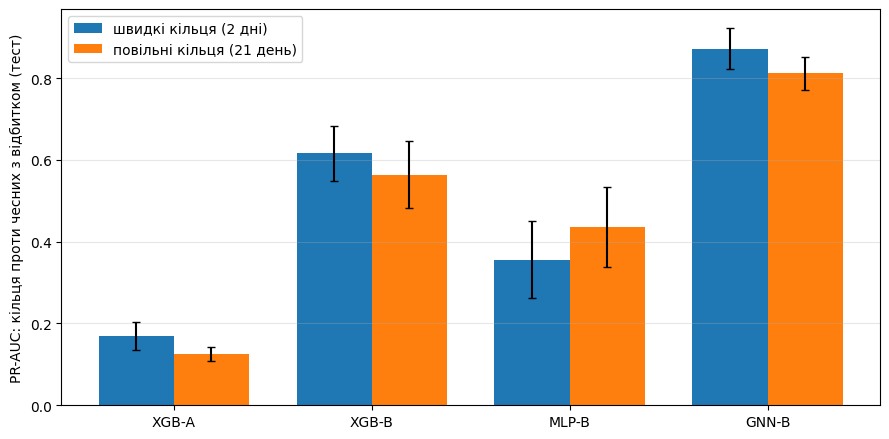

In [8]:
san = pd.read_csv(SAN_PATH); print("санітарна перевірка (після зважування):")
display(san.groupby("setting")[["ratio_table", "ratio_freq_only"]].agg(["mean", "min", "max"]).round(2))
R = pd.DataFrame(ALL_ROWS)
if len(R) == 0:
    print("експерименти не запускались: санітарна перевірка не пройдена в жодному режимі")
else:
    cols = ["усі", FM, "лише справжні"]
    for setting, g in R.groupby("setting"):
        print("\n==", setting, f"(seed: {g.seed.nunique()}) == середнє ± std")
        display(g.groupby("модель")[cols].agg(["mean", "std"]).reindex(MN).round(3))
        pv = g.pivot(index="seed", columns="модель", values=FM)
        d = pv[MN[3]] - pv[[MN[1], MN[2]]].max(axis=1)
        t, p = stats.ttest_1samp(d, 0.0)
        print(f"GNN-B − max(XGB-B, MLP-B): {d.mean():+.4f} ± {d.std()/np.sqrt(len(d)):.4f} (SE), "
              f"p = {p:.3f} → підтверджено (> 0,01 і p < 0,025): {bool(d.mean() > 0.01 and p < 0.025)}")
        print("стеля (XGB-B > 0,9)?", bool(pv[MN[1]].mean() > 0.9))
    s = R.groupby(["setting", "модель"])[FM].agg(["mean", "std"]).unstack("setting")
    sets = sorted(R.setting.unique(), reverse=True)
    fig, ax = plt.subplots(figsize=(9, 4.5)); x = np.arange(len(MN)); wd = 0.38
    for k, (setting, c) in enumerate(zip(sets, ["tab:blue", "tab:orange"])):
        m_ = s["mean"][setting].reindex(MN); e_ = s["std"][setting].reindex(MN)
        ax.bar(x + (k - (len(sets) - 1) / 2) * wd, m_.values, wd, yerr=e_.values, capsize=3, label=setting, color=c)
    ax.set_xticks(x); ax.set_xticklabels(["XGB-A", "XGB-B", "MLP-B", "GNN-B"])
    ax.set_ylabel("PR-AUC: кільця проти чесних з відбитком (тест)"); ax.legend(); ax.grid(axis="y", alpha=0.3)
    plt.tight_layout(); plt.savefig("results/figures/ieee_cis_stress_test.png", dpi=200); plt.show()